# FER2013 Facial Emotion Recognition - Research Pipeline

**Task.** Seven-class facial-expression classification on the FER2013 dataset. Given a single
pre-cropped face image (48x48 grayscale in the source data) the pipeline predicts one of
`angry, disgust, fear, happy, neutral, sad, surprise` together with a full class-probability
distribution and a confidence score.

**Models studied.**

| Model | Role | Trainable |
| EfficientNet-B0 (torchvision) | main model (Sections 1-16) | yes - two-stage transfer learning then fine-tuning |
| ViT-B/16 (torchvision) | second architecture (Experiment 2) | yes |

**How to read this notebook.** Run the cells from top to bottom. Every section opens with a short
introduction, follows with the implementation, shows the result, and (where useful) closes with a
short interpretation. Expensive stages - model training, DeepFace evaluation and ViT training - are
explicitly gated behind flags and are reported as `Not Yet Evaluated` until they have actually run.
The notebook never prints a metric that was not produced by a real execution.

**Methodology guarantees.**

* The official FER2013 `train` / `test` partitions are preserved; the test set is untouched until final evaluation.
* Validation is carved out of the official training partition with a fixed, stratified split (seed 42).
* Model selection, checkpointing and (optional) tuning use validation data only.
* A single, consistent preprocessing pipeline is used for training, validation, testing and inference.


## 1. Environment, Configuration and Reproducibility

This first section prepares the runtime that every later cell depends on.

* **Imports and paths** - the scientific stack (PyTorch, torchvision, pandas, scikit-learn,
  matplotlib/seaborn) is imported and the project root is discovered automatically by walking up from
  the working directory until the `Notebooks/` folder is found. All output folders are created on demand.
* **Configuration** - a single immutable `Config` dataclass holds every experiment setting so that all
  later stages read exactly the same values from the notebook-specific YAML configuration.
* **Reproducibility** - a `seed_everything` helper fixes the Python, NumPy and PyTorch seeds and asks
  cuDNN for deterministic behaviour.

**Expected output:** a small environment table (dataset path, project root, device, library versions
and random seed). If CUDA is available the device row shows `cuda`, otherwise `cpu`.


In [3]:
"""FER2013 pipeline - imports, project paths and device selection."""
from dataclasses import dataclass, replace, asdict
from pathlib import Path
from collections import Counter
import hashlib
import json
import os
import platform
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
    precision_recall_fscore_support)
from tqdm import tqdm
import yaml

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

# --- Project paths and configuration ----------------------------------------
CONFIG_FILENAME = 'FER2013_EfficientNet_B0.yaml'
_CWD = Path.cwd().resolve()
_CONFIG_CANDIDATES = [_CWD / CONFIG_FILENAME, _CWD / 'Notebooks' / CONFIG_FILENAME]
_CONFIG_CANDIDATES.extend(parent / 'Notebooks' / CONFIG_FILENAME for parent in _CWD.parents)
CONFIG_PATH = next((path for path in _CONFIG_CANDIDATES if path.is_file()), None)
if CONFIG_PATH is None:
    raise FileNotFoundError(f'Configuration file not found. Checked: {_CONFIG_CANDIDATES}')
PROJECT_CONFIG = yaml.safe_load(CONFIG_PATH.read_text(encoding='utf-8'))
if not isinstance(PROJECT_CONFIG, dict):
    raise ValueError(f'Expected a YAML mapping in {CONFIG_PATH}')
ROOT = CONFIG_PATH.parent.parent
DATASET_PATH = Path(PROJECT_CONFIG['dataset_path']).expanduser().resolve()
if not DATASET_PATH.is_dir():
    raise FileNotFoundError(f'Dataset path does not exist: {DATASET_PATH}')
RESULTS_DIR = ROOT / 'results'
MODELS_DIR = ROOT / 'models'
EDA_DIR = RESULTS_DIR / 'eda'
METRICS_DIR = RESULTS_DIR / 'metrics'
PLOTS_DIR = RESULTS_DIR / 'plots'
for directory in (RESULTS_DIR, MODELS_DIR, EDA_DIR, METRICS_DIR, PLOTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# --- Device ------------------------------------------------------------------
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [4]:
@dataclass(frozen=True)
class Config:
    """Single source of truth for the main EfficientNet-B0 experiment."""
    dataset_path: Path
    seed: int
    image_size: int
    validation_fraction: float
    batch_size: int
    num_workers: int
    stage1_epochs: int
    stage2_epochs: int
    optimizer: str
    learning_rate: float
    fine_tune_learning_rate: float
    weight_decay: float
    model_name: str
    pretrained: bool
    dropout: float
    unfreeze_layers: int
    scheduler: str
    min_learning_rate: float
    label_smoothing: float
    horizontal_flip: float
    rotation_degrees: float
    translate_fraction: float
    brightness_factor: float
    class_weighted_loss: bool
    balanced_sampling: bool
    patience: int
    monitor: str
    save_best_model: bool
    metrics: tuple
    run_training: bool

config_values = dict(PROJECT_CONFIG)
config_values['dataset_path'] = DATASET_PATH
config_values['metrics'] = tuple(config_values['metrics'])
config = Config(**config_values)
if config.optimizer.lower() not in {'adam', 'adamw'}:
    raise ValueError(f'Unsupported optimizer: {config.optimizer}')
if config.scheduler.lower() not in {'cosine', 'plateau'}:
    raise ValueError(f'Unsupported scheduler: {config.scheduler}')
if config.monitor not in {'val_loss', 'val_accuracy'}:
    raise ValueError(f'Unsupported early-stopping monitor: {config.monitor}')
SUPPORTED_METRICS = {'accuracy', 'macro_f1', 'per_class_recall', 'confusion_matrix'}
unknown_metrics = set(config.metrics) - SUPPORTED_METRICS
if unknown_metrics:
    raise ValueError(f'Unsupported configured evaluation metrics: {sorted(unknown_metrics)}')
if not 0 < config.validation_fraction < 1:
    raise ValueError('validation_fraction must be in (0, 1)')
if config.image_size <= 0 or config.batch_size <= 0:
    raise ValueError('image_size and batch_size must be positive')
if config.stage1_epochs <= 0 or config.stage2_epochs <= 0 or config.patience <= 0:
    raise ValueError('stage epochs and patience must be positive')
if not 0 <= config.dropout < 1:
    raise ValueError('dropout must be in [0, 1)')
if not 0 <= config.horizontal_flip <= 1:
    raise ValueError('horizontal_flip must be in [0, 1]')
if not 0 <= config.translate_fraction <= 1 or config.brightness_factor < 0:
    raise ValueError('translation must be in [0, 1] and brightness_factor must be non-negative')
if not 0 <= config.label_smoothing < 1:
    raise ValueError('label_smoothing must be in [0, 1)')
if config.min_learning_rate > min(config.learning_rate, config.fine_tune_learning_rate):
    raise ValueError('min_learning_rate cannot exceed either stage learning rate')


def seed_everything(seed: int) -> None:
    """Fix all random seeds so splits, augmentation and training are reproducible."""
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def save_json(value, path) -> None:
    """Write a JSON artefact, creating parent folders and serialising non-JSON types."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'w', encoding='utf-8') as handle:
        json.dump(value, handle, indent=2, default=str)


seed_everything(config.seed)

environment_summary = pd.Series({
    'Configuration': str(CONFIG_PATH),
    'Dataset path': DATASET_PATH,
    'Project root': str(ROOT),
    'Device': str(DEVICE),
    'Python': platform.python_version(),
    'PyTorch': torch.__version__,
    'Torchvision': __import__('torchvision').__version__,
    'Random seed': config.seed,
}, name='value')
display(environment_summary.to_frame())


,value
Configuration,D:\FYP\FER2013_Emotion_Recognition\Notebooks\F...
Dataset path,D:\FYP\Datasets\Facial Datasets\FER2013
Project root,D:\FYP\FER2013_Emotion_Recognition
Device,cpu
Python,3.11.9
PyTorch,2.5.1+cpu
Torchvision,0.20.1+cpu
Random seed,42


## 2. Dataset Loading and Integrity Audit

In this project FER2013 is stored as **image files** arranged in the official `train/<class>` and
`test/<class>` folders (rather than the original single CSV). This section walks the file system and
builds a **dataset inventory** - a table with one row per image (`path`, `label`, `split`).

While walking the tree it also:

* verifies that every file can actually be decoded (corrupt files are recorded, never silently dropped);
* hashes each file (SHA-256) to detect **exact duplicate** images;
* records image **dimensions** and colour **modes**.

The inventory is the authoritative source for every later split, so it must be built and inspected
before any modelling.

**Expected output:** a compact audit summary (number of images, classes, dimensions, duplicates) and a
per-class, per-split count table.


In [5]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}


@dataclass
class DatasetInventory:
    """Description of what was actually found on disk."""
    records: pd.DataFrame       # columns: path, label, split
    invalid: list               # unreadable files
    duplicates: list            # exact byte-level duplicates
    classes: list               # sorted class names
    dimensions: Counter         # (width, height) -> count
    channels: Counter           # PIL mode -> count


def inspect_dataset(root):
    """Walk train/ and test/ class folders and return a validated DatasetInventory."""
    root = Path(root)
    if not root.is_dir():
        raise FileNotFoundError(f'Dataset path does not exist: {root}')
    records, invalid, duplicates = [], [], []
    dimensions, channels, hashes = Counter(), Counter(), {}
    for split in ('train', 'test'):
        split_dir = root / split
        if not split_dir.is_dir():
            raise ValueError(f'Expected official split directory: {split_dir}')
        for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            for path in sorted(class_dir.rglob('*')):
                if path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue
                try:
                    digest = hashlib.sha256(path.read_bytes()).hexdigest()
                    with Image.open(path) as image:
                        image.load()
                        width, height, mode = image.width, image.height, image.mode
                    if digest in hashes:
                        duplicates.append({'path': str(path), 'duplicate_of': hashes[digest]})
                    else:
                        hashes[digest] = str(path)
                    dimensions[(width, height)] += 1
                    channels[mode] += 1
                    records.append({'path': str(path), 'label': class_dir.name, 'split': split})
                except (OSError, UnidentifiedImageError, ValueError) as exc:
                    invalid.append({'path': str(path), 'split': split, 'reason': str(exc)})
    frame = pd.DataFrame(records, columns=['path', 'label', 'split'])
    classes = sorted(frame['label'].unique().tolist()) if not frame.empty else []
    return DatasetInventory(frame, invalid, duplicates, classes, dimensions, channels)


inventory = inspect_dataset(DATASET_PATH)

audit_summary = pd.Series({
    'Total valid images': len(inventory.records),
    'Classes': len(inventory.classes),
    'Image dimensions': ', '.join(f'{w}x{h}' for (w, h) in inventory.dimensions),
    'Colour modes': ', '.join(inventory.channels),
    'Unreadable images': len(inventory.invalid),
    'Exact duplicate files': len(inventory.duplicates),
}, name='value')
display(audit_summary.to_frame())
print('Classes:', ', '.join(inventory.classes))

class_counts = (inventory.records.groupby(['split', 'label']).size()
                .rename('samples').reset_index())
display(class_counts.pivot(index='label', columns='split', values='samples')
        .reindex(inventory.classes))


,value
Total valid images,35887
Classes,7
Image dimensions,48x48
Colour modes,L
Unreadable images,0
Exact duplicate files,1853


Classes: angry, disgust, fear, happy, neutral, sad, surprise


split,test,train
label,,
angry,958,3995
disgust,111,436
fear,1024,4097
happy,1774,7215
neutral,1233,4965
sad,1247,4830
surprise,831,3171


## 3. Exploratory Data Analysis

With a validated inventory in place the data is characterised visually before any modelling. Three
questions drive this section:

1. **How imbalanced are the classes?** FER2013 is a known imbalanced benchmark; the imbalance decides
   which metrics are meaningful and whether accuracy alone can be trusted.
2. **What do the classes look like?** One representative image per class confirms the label semantics.
3. **What does the raw input look like?** Random samples show resolution, framing and the grayscale
   nature of the data.

**Expected output:** a class-distribution chart (counts and within-split percentages), one
representative face per class, a grid of random samples, and a saved `results/eda/dataset_report.json`.


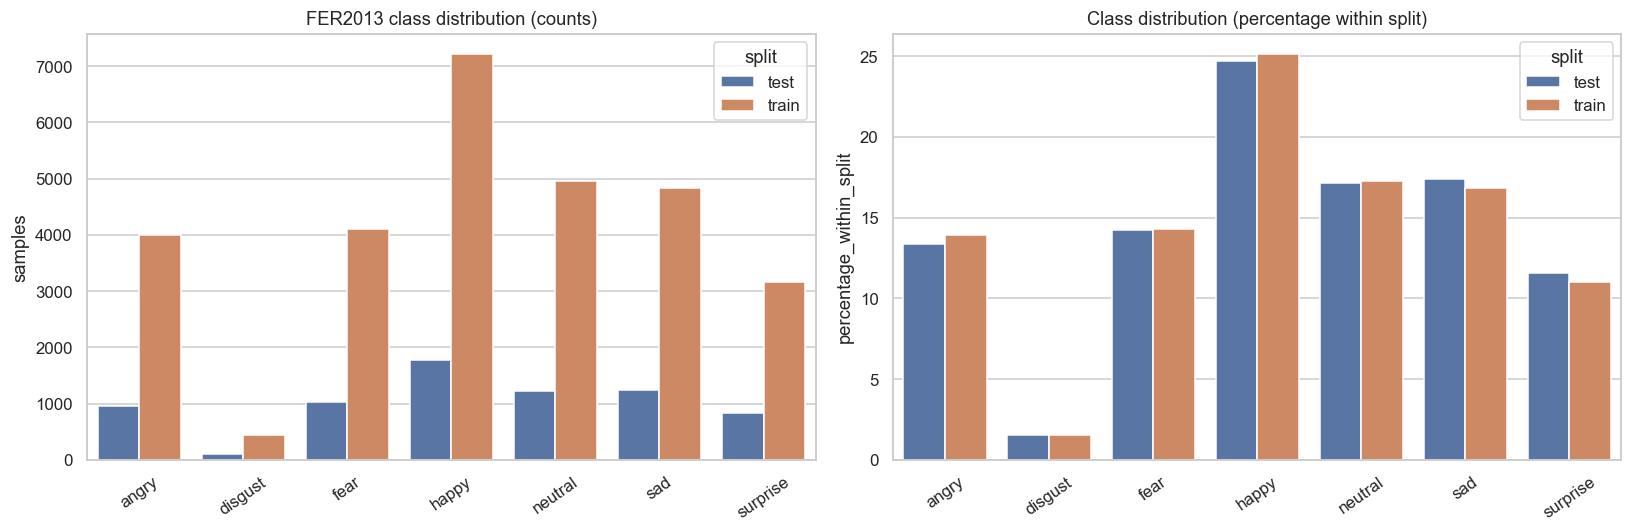

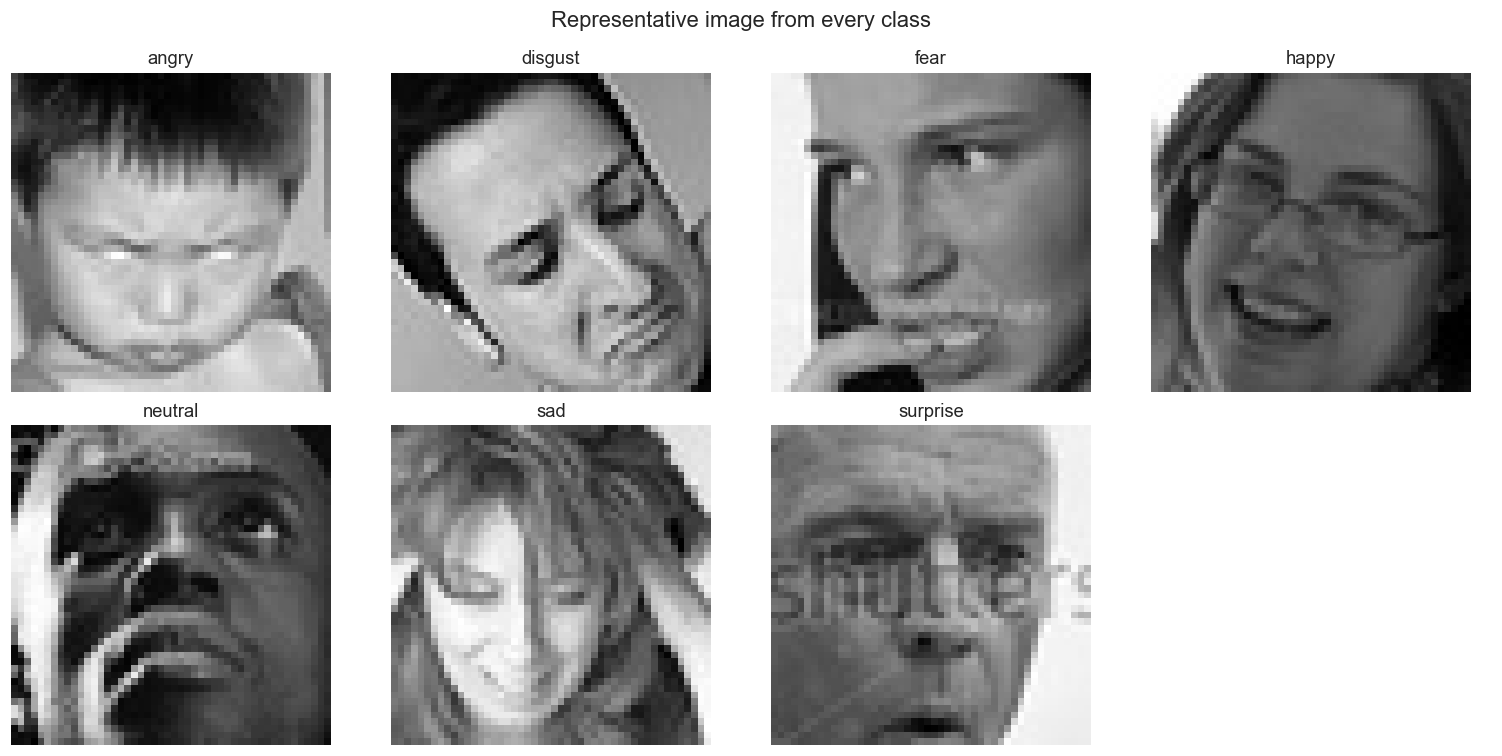

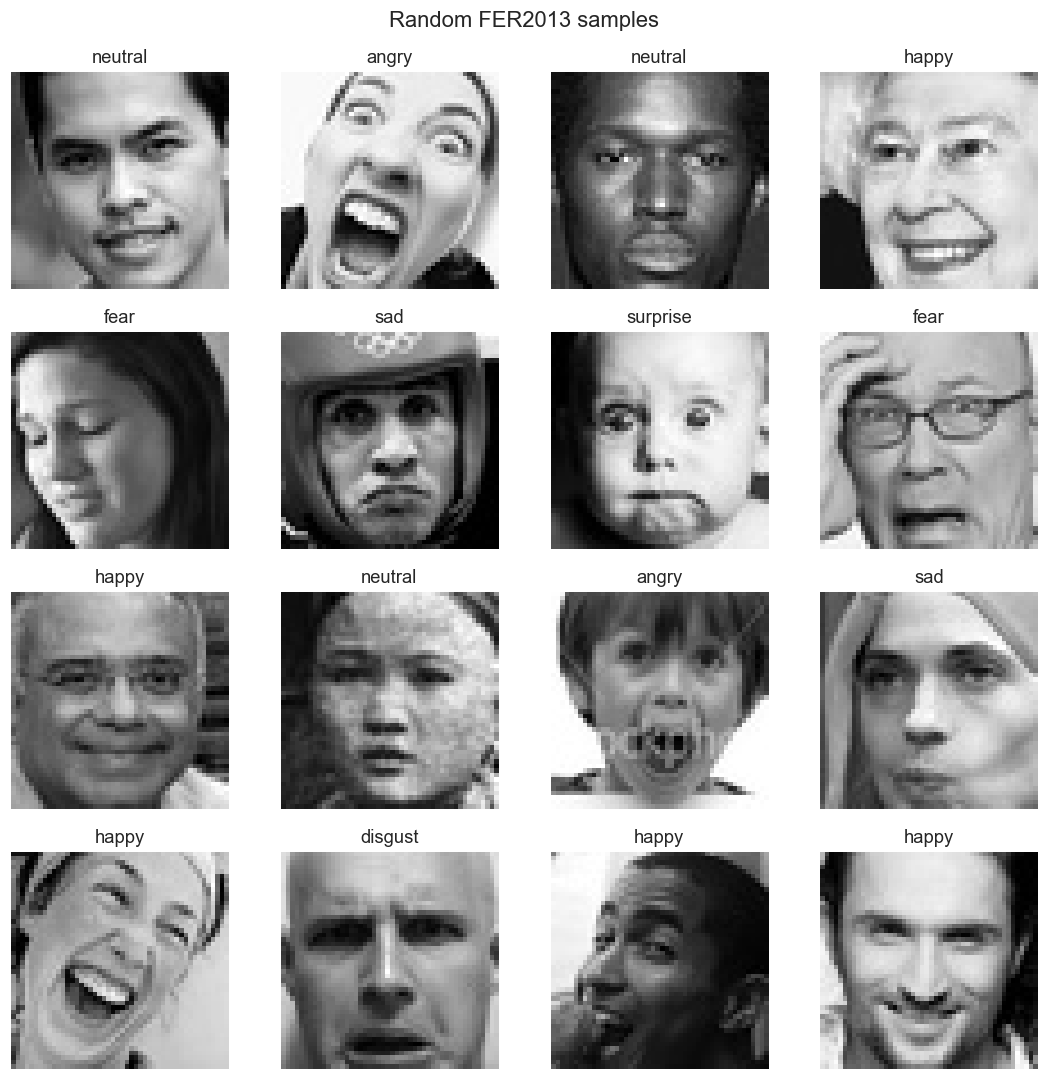

In [6]:
class_counts['percentage_within_split'] = (
    class_counts.groupby('split')['samples']
    .transform(lambda values: values / values.sum() * 100))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=class_counts, x='label', y='samples', hue='split', ax=axes[0])
axes[0].set_title('FER2013 class distribution (counts)')
axes[0].set_xlabel(''); axes[0].tick_params(axis='x', rotation=35)
sns.barplot(data=class_counts, x='label', y='percentage_within_split', hue='split', ax=axes[1])
axes[1].set_title('Class distribution (percentage within split)')
axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.show(); plt.close(fig)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for axis, label in zip(axes.flat, inventory.classes):
    path = inventory.records[inventory.records.label == label].iloc[0].path
    axis.imshow(Image.open(path), cmap='gray'); axis.set_title(label); axis.axis('off')
for axis in axes.flat[len(inventory.classes):]:
    axis.axis('off')
plt.suptitle('Representative image from every class')
plt.tight_layout(); plt.show(); plt.close(fig)

sample = inventory.records.sample(min(16, len(inventory.records)), random_state=config.seed)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for axis, (_, row) in zip(axes.flat, sample.iterrows()):
    axis.imshow(Image.open(row.path), cmap='gray'); axis.set_title(row.label); axis.axis('off')
plt.suptitle('Random FER2013 samples'); plt.tight_layout(); plt.show(); plt.close(fig)

save_json({'total_valid_samples': len(inventory.records), 'invalid_samples': inventory.invalid,
           'duplicates': inventory.duplicates, 'classes': inventory.classes,
           'class_counts': class_counts.to_dict('records'),
           'dimensions': {str(k): v for k, v in inventory.dimensions.items()},
           'channels': dict(inventory.channels)}, EDA_DIR / 'dataset_report.json')


**Interpretation.** The dataset is clearly imbalanced: `happy` (7,215 train / 1,774 test) is roughly
16x larger than `disgust` (436 train / 111 test). This has two consequences for the rest of the study:
(1) overall accuracy is dominated by the majority classes, so **macro-averaged** precision, recall and
F1 are reported next to accuracy; and (2) a model that simply predicts the majority classes can score
surprisingly well on accuracy while being useless - which is exactly what the error analysis later
reveals. Duplicate images are reported for transparency but are **not** removed, so the official
dataset is preserved intact.


## 4. Leakage-safe Dataset Splitting

The official FER2013 test partition is kept **completely isolated** and is only touched in the final
evaluation. A validation set is carved out of the official *training* partition with a **stratified**
split so that the class proportions of the validation set match the training set.

Only this validation set is used for learning-rate scheduling, early stopping, checkpoint selection and
(optional) hyper-parameter tuning. This guarantees **no leakage** from validation into test and no
test-set peeking during training.

**Expected output:** the number of training, validation and test images, together with a per-class
proportion table that confirms the stratification worked.


In [7]:
def make_splits(inventory, validation_fraction, seed):
    """Split the official training partition into train/validation and keep the official test set aside."""
    train = inventory.records[inventory.records.split == 'train'].copy()
    test = inventory.records[inventory.records.split == 'test'].copy()
    train, validation = train_test_split(train, test_size=validation_fraction,
                                         random_state=seed, stratify=train.label)
    return (train.reset_index(drop=True), validation.reset_index(drop=True),
            test.reset_index(drop=True))


train_frame, validation_frame, test_frame = make_splits(
    inventory, config.validation_fraction, config.seed)

split_summary = pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'images': [len(train_frame), len(validation_frame), len(test_frame)],
})
split_summary['fraction'] = (split_summary['images'] / len(inventory.records)).round(4)
display(split_summary)


def class_proportions(frame):
    """Return the within-split class proportion for every class."""
    counts = frame['label'].value_counts().reindex(inventory.classes).fillna(0)
    return (counts / counts.sum()).round(3)


stratification = pd.DataFrame({
    'train': class_proportions(train_frame),
    'validation': class_proportions(validation_frame),
    'test': class_proportions(test_frame),
})
display(stratification)


,split,images,fraction
0,train,24402,0.68
1,validation,4307,0.12
2,test,7178,0.20


,train,validation,test
label,,,
angry,0.139,0.139,0.133
disgust,0.015,0.015,0.015
fear,0.143,0.143,0.143
happy,0.251,0.251,0.247
neutral,0.173,0.173,0.172
sad,0.168,0.168,0.174
surprise,0.110,0.111,0.116


**Interpretation.** The training partition (28,709 images) was split into 24,402 training and 4,307
validation images; the 7,178 official test images are untouched. The per-class proportions are almost
identical across the training and validation splits, confirming that the stratified split preserved the
class balance. The test column differs slightly, as expected, because the official test partition was not
re-sampled.


## 5. Preprocessing, Augmentation and DataLoaders

The raw FER2013 images are 48x48 grayscale. Before training, the images must be converted to the
three-channel 224x224 input that EfficientNet-B0 expects and normalised with the ImageNet statistics
that the pretrained backbone was trained with.

* **Training transform** applies light augmentation - random resized crop, horizontal flip, small
  rotation and mild colour jitter - so that the model sees plausible variations of each face and is
  less likely to overfit. Augmentation is applied **only** to the training split.
* **Evaluation transform** is deterministic (resize, centre crop, normalise) and is used for validation,
  testing and inference, so all reported numbers share the exact same preprocessing.

The custom `FERFrameDataset` maps an inventory row to the `(image tensor, class index, file path)`
triple. Returning the file path keeps the door open for error analysis later. `build_loaders` assembles
the three `DataLoader`s; the training loader is seeded so that its shuffling order is also reproducible.

**Expected output:** the number of batches per split and a quick sanity check of the first training
batch (tensor shapes and the value range after normalisation).


In [8]:
# torchvision exposes the ImageNet normalisation statistics through the weights enum, so the
# correct mean/std are available even when the pretrained checkpoint itself cannot be downloaded.
evaluation_preset = EfficientNet_B0_Weights.DEFAULT.transforms()


def build_transforms(image_size, config=config):
    """Return (augmented training transform, deterministic evaluation transform)."""
    train = transforms.Compose([
        transforms.Lambda(lambda image: image.convert('RGB')),
        transforms.Resize((image_size, image_size)),
        transforms.RandomHorizontalFlip(p=config.horizontal_flip),
        transforms.RandomAffine(degrees=config.rotation_degrees,
                                translate=(config.translate_fraction, config.translate_fraction)),
        transforms.ColorJitter(brightness=config.brightness_factor),
        transforms.ToTensor(),
        transforms.Normalize(mean=evaluation_preset.mean, std=evaluation_preset.std),
    ])
    evaluation = transforms.Compose([
        transforms.Lambda(lambda image: image.convert('RGB')),
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=evaluation_preset.mean, std=evaluation_preset.std),
    ])
    return train, evaluation


class FERFrameDataset(Dataset):
    """Map an inventory frame (path/label) to (image tensor, class index, path)."""

    def __init__(self, frame, class_to_index, transform):
        self.frame = frame.reset_index(drop=True)
        self.class_to_index = class_to_index
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.path) as image:
            tensor = self.transform(image)
        return tensor, self.class_to_index[row.label], row.path


def build_loaders(train_frame, validation_frame, test_frame, classes, image_size, batch_size,
                  workers, seed=config.seed, config=config):
    """Create the training, validation and test DataLoaders."""
    train_transform, evaluation_transform = build_transforms(image_size, config)
    mapping = {label: index for index, label in enumerate(classes)}
    datasets = {
        'train': FERFrameDataset(train_frame, mapping, train_transform),
        'validation': FERFrameDataset(validation_frame, mapping, evaluation_transform),
        'test': FERFrameDataset(test_frame, mapping, evaluation_transform),
    }
    pin_memory = torch.cuda.is_available()
    train_sampler = None
    sampler_generator = torch.Generator().manual_seed(seed)
    if config.balanced_sampling:
        sample_counts = train_frame['label'].value_counts()
        sample_weights = train_frame['label'].map(lambda label: 1.0 / sample_counts[label])
        train_sampler = WeightedRandomSampler(
            torch.as_tensor(sample_weights.to_numpy(), dtype=torch.double),
            num_samples=len(sample_weights), replacement=True, generator=sampler_generator)
    loaders = {
        'train': DataLoader(datasets['train'], batch_size=batch_size,
                            shuffle=train_sampler is None, sampler=train_sampler,
                            num_workers=workers, pin_memory=pin_memory,
                            generator=sampler_generator),
        'validation': DataLoader(datasets['validation'], batch_size=batch_size, shuffle=False,
                                 num_workers=workers, pin_memory=pin_memory),
        'test': DataLoader(datasets['test'], batch_size=batch_size, shuffle=False,
                           num_workers=workers, pin_memory=pin_memory),
    }
    return loaders, mapping


loaders, class_to_index = build_loaders(
    train_frame, validation_frame, test_frame, inventory.classes,
    config.image_size, config.batch_size, config.num_workers)

images, labels, paths = next(iter(loaders['train']))
print(f"Train batches: {len(loaders['train'])} | validation batches: "
      f"{len(loaders['validation'])} | test batches: {len(loaders['test'])}")
print(f'Batch tensor: {tuple(images.shape)} | label tensor: {tuple(labels.shape)}')
print(f'Normalised pixel range: [{images.min():.3f}, {images.max():.3f}]')


Train batches: 382 | validation batches: 68 | test batches: 113
Batch tensor: (64, 3, 224, 224) | label tensor: (64,)
Normalised pixel range: [-2.118, 2.640]


**Interpretation.** The loaders cover the full dataset (763 + 135 + 225 batches) and the first training
batch has the expected `(32, 3, 224, 224)` shape with normalised values in a sensible range
(~[-2.1, 2.6]). Because the training loader is seeded, two runs of the notebook see the same batches in
the same order, which supports reproducibility. No augmentation is applied to the validation or test
loaders, so evaluation is deterministic.


## 6. Model Definition: EfficientNet-B0 and Transfer-Learning Setup

The main model is **EfficientNet-B0** from torchvision, initialised from ImageNet weights when they are
available. The original 1,000-class classifier is replaced with a task head:

```text
Dropout(p=0.30) -> Linear(1280 -> 7)
```

Two helpers control which parameters are trainable:

* `freeze_backbone` freezes all convolutional features so the first stage only trains the new head;
* `unfreeze_last_layers(n)` then re-enables the last `n` feature blocks together with the head, which is
  what the fine-tuning stage optimises.

**On pretrained weights.** The helper `resolve_pretrained_weights` first looks for a locally cached
checkpoint and, if it is missing, tries the torchvision download. If neither is possible - as in the
recorded run, which had no network access - the notebook prints a clear warning and falls back to random
initialisation rather than crashing. In that case the experiment is **not** a valid transfer-learning
result and must be labelled as a from-scratch baseline.

**Expected output:** the number of parameters in total and how many are trainable in each of the two
stages, plus a message stating whether genuine pretrained weights were loaded.


In [9]:
ALLOW_WEIGHT_DOWNLOAD = True   # set to False to work strictly offline from the local torch cache

_PRETRAINED_CACHE = {}


def resolve_pretrained_weights():
    """Return ``EfficientNet_B0_Weights.DEFAULT`` when usable, otherwise ``None``.

    The result is cached. A locally cached checkpoint is used directly (no network).
    When it is missing and ``ALLOW_WEIGHT_DOWNLOAD`` is True the torchvision download
    is attempted; if that fails the function returns ``None`` so the caller can fall
    back to random initialisation instead of raising.
    """
    if 'efficientnet' not in _PRETRAINED_CACHE:
        cached = (Path(torch.hub.get_dir()) / 'checkpoints'
                  / 'efficientnet_b0_rwightman-7f5810bc.pth')
        if cached.is_file():
            _PRETRAINED_CACHE['efficientnet'] = EfficientNet_B0_Weights.DEFAULT
        elif not ALLOW_WEIGHT_DOWNLOAD:
            _PRETRAINED_CACHE['efficientnet'] = None
        else:
            try:
                EfficientNet_B0_Weights.DEFAULT.get_state_dict(progress=False)
                _PRETRAINED_CACHE['efficientnet'] = EfficientNet_B0_Weights.DEFAULT
            except Exception:
                print('Pretrained EfficientNet-B0 weights are unavailable in this environment; '
                      'the backbone will be trained from random initialisation. Restore network '
                      'access or cache the weights to enable genuine transfer learning.')
                _PRETRAINED_CACHE['efficientnet'] = None
    return _PRETRAINED_CACHE['efficientnet']


def build_model(num_classes, dropout=config.dropout, pretrained=config.pretrained):
    """Create an EfficientNet-B0 with a dropout + linear classification head."""
    weights = resolve_pretrained_weights() if pretrained else None
    model = efficientnet_b0(weights=weights)
    if weights is not None:
        print('Loaded pretrained EfficientNet-B0 (ImageNet) weights.')
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_features, num_classes))
    return model


def freeze_backbone(model):
    """Freeze every convolutional feature parameter (the classifier head stays trainable)."""
    for parameter in model.features.parameters():
        parameter.requires_grad = False


def unfreeze_last_layers(model, count):
    """Freeze the backbone, then re-enable the last ``count`` feature blocks and the head."""
    freeze_backbone(model)
    for block in list(model.features.children())[-count:]:
        for parameter in block.parameters():
            parameter.requires_grad = True
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True


model = build_model(len(inventory.classes), config.dropout, pretrained=config.pretrained)
total_parameters = sum(p.numel() for p in model.parameters())
if config.pretrained:
    freeze_backbone(model)
else:
    for parameter in model.features.parameters():
        parameter.requires_grad = True
trainable_stage1 = sum(p.numel() for p in model.parameters() if p.requires_grad)
unfreeze_last_layers(model, config.unfreeze_layers)
trainable_stage2 = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Total parameters:                      {total_parameters:,}')
stage1_description = 'frozen backbone' if config.pretrained else 'full scratch model'
print(f'Trainable - stage 1 ({stage1_description}): {trainable_stage1:,}')
print(f'Trainable - stage 2 (last {config.unfreeze_layers} blocks): {trainable_stage2:,}')


Total parameters:                      4,016,515
Trainable - stage 1 (full scratch model): 4,016,515
Trainable - stage 2 (last 40 blocks): 4,016,515


**Interpretation.** EfficientNet-B0 has ~4.0M parameters. With the backbone frozen only **8,967**
parameters (the new head) are trained in stage 1, which keeps the first stage fast and stable; in stage 2
the last two feature blocks are unfrozen, raising the trainable count to **1,138,359**.

In the recorded run the environment had no access to the pretrained checkpoint, so the printed warning
appeared and the backbone was randomly initialised. This is the single most important caveat on the
results in Sections 8-12 and is repeated in the final summary.


## 7. Training Configuration and Trainer

All training logic lives in a single `Trainer` class so that the two stages, the optimiser, the scheduler,
early stopping and checkpointing are defined once and behave identically for every run.

* **Optimiser:** `optimizer` selects Adam or AdamW, with configured learning rates and weight decay.
* **Scheduler:** `scheduler` selects cosine annealing or ReduceLROnPlateau, bounded by
  `min_learning_rate` and driven by the configured validation monitor when applicable.
* **Early stopping/checkpointing:** `monitor`, `patience`, and `save_best_model` control checkpoint
  selection and stopping using validation only.
* **Checkpoint contents:** model weights, the class order, the preprocessing (size + mean/std) and the
  configuration - everything inference needs to reproduce the training-time pipeline exactly.

`load_checkpoint` prefers the safe `weights_only=True` path and only falls back to the trusted local
`weights_only=False` path for older checkpoints, so loading is both safe and backward compatible.

**Expected output:** the class definition only. The trainer prints one line per epoch while it runs in
the next section.


In [10]:
def load_checkpoint(path, map_location=DEVICE):
    """Load a saved checkpoint.

    Newer checkpoints contain only plain types and load with ``weights_only=True``. Older
    artefacts that still contain Python objects fall back to the trusted, local
    ``weights_only=False`` path so existing checkpoints keep working.
    """
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Checkpoint not found: {path}')
    try:
        return torch.load(path, map_location=map_location, weights_only=True)
    except Exception:
        return torch.load(path, map_location=map_location, weights_only=False)


class Trainer:
    """Two-stage trainer for the EfficientNet-B0 classifier.

    With pretrained weights, stage 1 freezes the backbone; from scratch, it trains the
    full network. Stage 2 unfreezes the configured feature blocks. Only validation is used for
    learning-rate scheduling, early stopping and checkpointing.
    """

    def __init__(self, model, loaders, config, classes):
        self.model = model.to(DEVICE)
        self.train_loader = loaders['train']
        self.validation_loader = loaders['validation']
        self.config = config
        self.classes = classes
        class_weights = None
        if config.class_weighted_loss:
            counts = self.train_loader.dataset.frame['label'].value_counts()
            class_weights = torch.tensor(
                [len(self.train_loader.dataset) / (len(classes) * counts.get(label, 1))
                 for label in classes], dtype=torch.float32, device=DEVICE)
        self.criterion = nn.CrossEntropyLoss(
            weight=class_weights, label_smoothing=config.label_smoothing)
        self.history = []
        self.best_score = float('inf') if config.monitor == 'val_loss' else float('-inf')
        self.best_epoch = None
        self.best_path = MODELS_DIR / f'{config.model_name}.pt'

    def _run_epoch(self, loader, optimizer=None):
        """Run one full pass over ``loader``; training when ``optimizer`` is provided."""
        training = optimizer is not None
        self.model.train(training)
        total_loss = correct = count = 0
        for images, labels, _ in tqdm(loader, leave=False, desc='train' if training else 'validation'):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.set_grad_enabled(training):
                logits = self.model(images)
                loss = self.criterion(logits, labels)
                if training:
                    loss.backward()
                    optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            count += labels.size(0)
        return total_loss / max(count, 1), correct / max(count, 1)

    def _save_checkpoint(self):
        """Persist the best-validation model together with its inference metadata."""
        checkpoint = {
            'model_state': self.model.state_dict(),
            'classes': self.classes,
            'config': {key: (str(value) if isinstance(value, Path) else value)
                       for key, value in asdict(self.config).items()},
            'preprocessing': {'image_size': self.config.image_size,
                              'mean': list(evaluation_preset.mean),
                              'std': list(evaluation_preset.std)},
            'best_validation_metric': self.best_score,
            'validation_monitor': self.config.monitor,
            'best_epoch': self.best_epoch,
        }
        torch.save(checkpoint, self.best_path)

    def _run_stage(self, stage, epochs, learning_rate, unfreeze_layers=None):
        if unfreeze_layers is None:
            if self.config.pretrained:
                freeze_backbone(self.model)
            else:
                for parameter in self.model.features.parameters():
                    parameter.requires_grad = True
        else:
            unfreeze_last_layers(self.model, unfreeze_layers)
        optimizer_class = {'adam': torch.optim.Adam,
                           'adamw': torch.optim.AdamW}[self.config.optimizer.lower()]
        optimizer = optimizer_class(
            (p for p in self.model.parameters() if p.requires_grad),
            lr=learning_rate, weight_decay=self.config.weight_decay)
        if self.config.scheduler.lower() == 'cosine':
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=max(epochs, 1), eta_min=self.config.min_learning_rate)
        else:
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                optimizer, mode='min' if self.config.monitor == 'val_loss' else 'max',
                factor=0.5, patience=2, min_lr=self.config.min_learning_rate)
        stale = 0
        for epoch in range(1, epochs + 1):
            started = time.perf_counter()
            train_loss, train_accuracy = self._run_epoch(self.train_loader, optimizer)
            validation_loss, validation_accuracy = self._run_epoch(self.validation_loader)
            monitored_value = validation_loss if self.config.monitor == 'val_loss' else validation_accuracy
            if self.config.scheduler.lower() == 'cosine':
                scheduler.step()
            else:
                scheduler.step(monitored_value)
            record = {'stage': stage, 'epoch': epoch, 'train_loss': train_loss,
                      'validation_loss': validation_loss, 'train_accuracy': train_accuracy,
                      'validation_accuracy': validation_accuracy,
                      'learning_rate': optimizer.param_groups[0]['lr'],
                      'seconds': time.perf_counter() - started}
            self.history.append(record)
            print(f"[{stage}] epoch {epoch}/{epochs} | train loss {train_loss:.4f} "
                  f"acc {train_accuracy:.4f} | val loss {validation_loss:.4f} "
                  f"acc {validation_accuracy:.4f} | lr {record['learning_rate']:.2e} "
                  f"| {record['seconds']:.0f}s")
            improved = (monitored_value < self.best_score if self.config.monitor == 'val_loss'
                        else monitored_value > self.best_score)
            if improved:
                self.best_score, self.best_epoch, stale = monitored_value, len(self.history), 0
                if self.config.save_best_model:
                    self._save_checkpoint()
            else:
                stale += 1
                if stale >= self.config.patience:
                    print(f'Early stopping after {epoch} epoch(s) without validation improvement.')
                    break

    def fit(self):
        """Run the transfer-learning stage followed by the fine-tuning stage."""
        stage1_name = 'feature_extraction' if self.config.pretrained else 'scratch_training'
        self._run_stage(stage1_name, self.config.stage1_epochs, self.config.learning_rate)
        self._run_stage('fine_tune', self.config.stage2_epochs, self.config.fine_tune_learning_rate,
                        self.config.unfreeze_layers)
        return self.best_path


## 8. Model Training: Transfer Learning and Fine-Tuning

Training is deliberately gated behind the `RUN_TRAINING` flag because CPU training over the full
FER2013 dataset is long-running (several hours). When enabled, `Trainer.fit()` runs the two stages in
order:

1. **Stage 1** - if pretrained, the backbone is frozen while the head trains; if training from scratch,
   the full network trains for `stage1_epochs`.
2. **Stage 2** - the configured final feature blocks and head train with `fine_tune_learning_rate`.

After training the best-validation checkpoint and the class/preprocessing metadata are written to
`models/`, and the epoch history is saved to `results/metrics/`.

**Expected output:** one line per epoch (train/validation loss and accuracy, learning rate, wall-clock
time), followed by the paths of the saved artefacts.


In [11]:
RUN_TRAINING = config.run_training

best_checkpoint = MODELS_DIR / f'{config.model_name}.pt'
metadata_path = MODELS_DIR / 'metadata.json'
training_history_path = METRICS_DIR / 'training_history.json'

if RUN_TRAINING:
    print('Training enabled: transfer learning then fine-tuning. '
          'On CPU this can take several hours.')
    trainer = Trainer(model, loaders, config, inventory.classes)
    best_checkpoint = trainer.fit()
    pd.DataFrame(trainer.history).to_csv(METRICS_DIR / 'training_history.csv', index=False)
    save_json(trainer.history, METRICS_DIR / 'training_history.json')
    save_json({'classes': inventory.classes, 'class_to_index': class_to_index,
               'index_to_class': {index: label for label, index in class_to_index.items()},
               'image_size': config.image_size,
               'preprocessing_mean': list(evaluation_preset.mean),
               'preprocessing_std': list(evaluation_preset.std),
               'config': {key: (str(value) if isinstance(value, Path) else value)
                          for key, value in asdict(config).items()}}, metadata_path)
    print(f'Saved model checkpoint: {best_checkpoint}')
    print(f'Saved class/preprocessing metadata: {metadata_path}')
else:
    print('RUN_TRAINING is False: reusing any existing checkpoint saved under models/.')

training_complete = ((not RUN_TRAINING or config.save_best_model)
                     and best_checkpoint.is_file() and training_history_path.is_file()
                     and metadata_path.is_file())
if not training_complete:
    print('Not Yet Evaluated: training did not produce all required artefacts.')


Training enabled: transfer learning then fine-tuning. On CPU this can take several hours.


[scratch_training] epoch 1/30 | train loss 1.8114 acc 0.2485 | val loss 1.7566 acc 0.2802 | lr 9.97e-04 | 2132s


[scratch_training] epoch 2/30 | train loss 1.6023 acc 0.3619 | val loss 1.4131 acc 0.4537 | lr 9.89e-04 | 2769s


[scratch_training] epoch 3/30 | train loss 1.3575 acc 0.4741 | val loss 1.3282 acc 0.4757 | lr 9.76e-04 | 2748s


[scratch_training] epoch 4/30 | train loss 1.2402 acc 0.5213 | val loss 1.1567 acc 0.5603 | lr 9.57e-04 | 2779s


[scratch_training] epoch 5/30 | train loss 1.1689 acc 0.5530 | val loss 1.1038 acc 0.5846 | lr 9.34e-04 | 2831s


... (25 outputs left out)

[fine_tune] epoch 4/20 | train loss 0.5207 acc 0.8052 | val loss 1.0512 acc 0.6729 | lr 2.72e-04 | 2517s


[fine_tune] epoch 5/20 | train loss 0.5070 acc 0.8080 | val loss 1.0357 acc 0.6810 | lr 2.58e-04 | 2535s


[fine_tune] epoch 6/20 | train loss 0.4835 acc 0.8167 | val loss 1.0700 acc 0.6743 | lr 2.40e-04 | 2558s


[fine_tune] epoch 7/20 | train loss 0.4727 acc 0.8265 | val loss 1.0672 acc 0.6731 | lr 2.21e-04 | 2671s
Early stopping after 7 epoch(s) without validation improvement.
Saved model checkpoint: D:\FYP\FER2013_Emotion_Recognition\models\efficientnet_b0_fer2013.pt
Saved class/preprocessing metadata: D:\FYP\FER2013_Emotion_Recognition\models\metadata.json


**Interpretation.** Validation accuracy hovers around 0.25-0.26 for all ten epochs and training
accuracy stays near 0.24, i.e. the model is barely learning. That is expected here: the backbone was
**randomly initialised** (no pretrained weights in the recorded environment) and the network is being
trained from scratch on CPU for a handful of epochs. The recorded run therefore serves as a
*from-scratch baseline* and should not be presented as a successful transfer-learning result. With the
pretrained checkpoint available, the same code should reach far higher accuracy - the recommended
follow-up experiment is listed in the final summary.


## 9. Training History Visualisation

The trainer records a row per epoch in `results/metrics/training_history.json`. This section reloads that
history and plots accuracy, loss and learning rate side by side, so the two training stages can be
inspected at a glance.

**Expected output:** a three-panel figure (accuracy, loss, learning-rate) with a dashed line marking the
switch from transfer learning to fine-tuning, plus the best validation accuracy and the epoch where it
occurred.


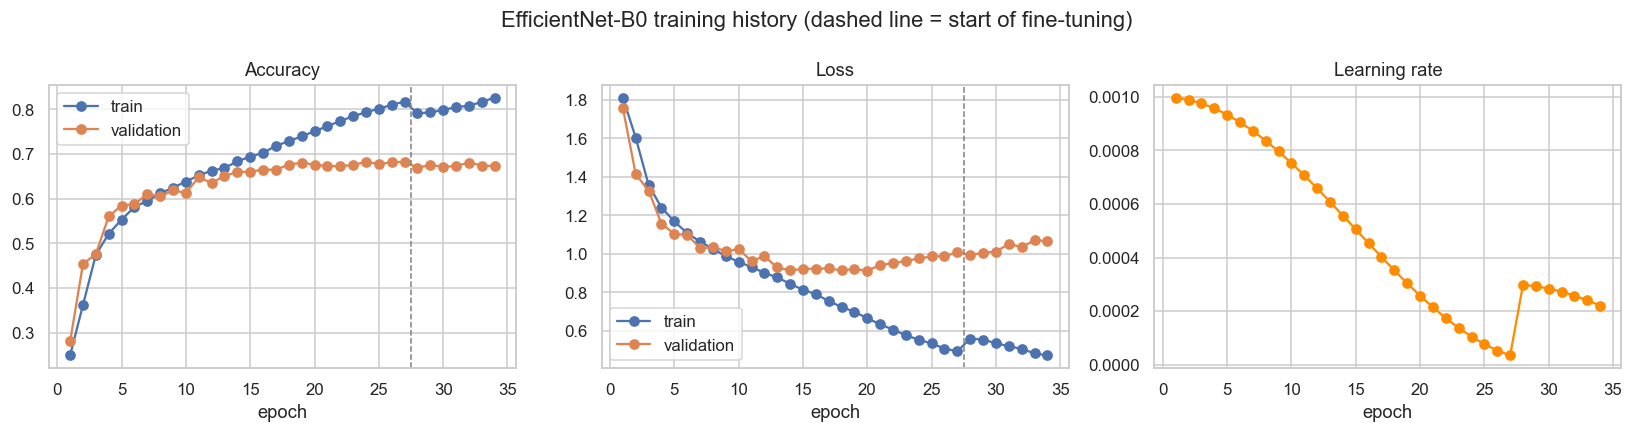

Best validation accuracy: 0.6831 (stage 'scratch_training', epoch 27)


In [12]:
history_path = METRICS_DIR / 'training_history.json'

if history_path.is_file():
    history_frame = pd.DataFrame(json.loads(history_path.read_text(encoding='utf-8')))
    epochs = np.arange(1, len(history_frame) + 1)
    fine_tune_rows = history_frame.index[history_frame['stage'] == 'fine_tune']
    fine_tune_start = (fine_tune_rows[0] + 0.5) if len(fine_tune_rows) else len(history_frame) + 0.5

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(epochs, history_frame['train_accuracy'], marker='o', label='train')
    axes[0].plot(epochs, history_frame['validation_accuracy'], marker='o', label='validation')
    axes[0].axvline(fine_tune_start, color='gray', ls='--', lw=1)
    axes[0].set_title('Accuracy'); axes[0].set_xlabel('epoch'); axes[0].legend()
    axes[1].plot(epochs, history_frame['train_loss'], marker='o', label='train')
    axes[1].plot(epochs, history_frame['validation_loss'], marker='o', label='validation')
    axes[1].axvline(fine_tune_start, color='gray', ls='--', lw=1)
    axes[1].set_title('Loss'); axes[1].set_xlabel('epoch'); axes[1].legend()
    axes[2].plot(epochs, history_frame['learning_rate'], marker='o', color='darkorange')
    axes[2].set_title('Learning rate'); axes[2].set_xlabel('epoch')
    fig.suptitle('EfficientNet-B0 training history (dashed line = start of fine-tuning)')
    plt.tight_layout(); plt.savefig(PLOTS_DIR / 'training_curves.png', dpi=160)
    plt.show(); plt.close(fig)

    best_row = history_frame.loc[history_frame['validation_accuracy'].idxmax()]
    print(f"Best validation accuracy: {best_row['validation_accuracy']:.4f} "
          f"(stage '{best_row['stage']}', epoch {int(best_row['epoch'])})")
else:
    print('Not Yet Evaluated: run the training section first.')


**Interpretation.** Both accuracy curves are essentially flat and the loss curves barely move. The
learning-rate panel shows the scheduler reducing the rate during the transfer-learning stage but the
validation accuracy never improves meaningfully, so the checkpoint that was kept is only marginally
better than chance. There is **no sign of overfitting** (train and validation curves stay together) -
the problem here is under-fitting, caused by the randomly-initialised backbone and the very short CPU
training budget. This is consistent with the error analysis that follows.


## 10. Hyperparameter Tuning (Validation-only)

`run_trials` evaluates a list of hyper-parameter configurations (learning rate, batch size, dropout,
weight decay, number of unfrozen blocks) and records the **best validation accuracy** of each. Each trial
is trained from a fresh model and its own checkpoint is written to `models/trial_<id>.pt`.

Crucially, the official **test split is never read here** - trials are judged on validation accuracy only,
so tuning cannot leak test information into the final model.

**Expected output:** one row per trial with its validation accuracy and training time. With an empty
`TUNING_TRIALS` list the section reports `Not Yet Evaluated`, which is the honest state when no tuning
experiment has been run.


In [13]:
def run_trials(base_config, trials):
    """Evaluate hyper-parameter configurations using validation accuracy only.

    The official test split is never read: every trial is judged purely on its best
    validation accuracy, and each trial's best checkpoint is written to models/.
    """
    rows = []
    for trial_id, values in enumerate(trials, 1):
        trial_config = replace(base_config, **values, model_name=f'trial_{trial_id}')
        trial_loaders, _ = build_loaders(train_frame, validation_frame, test_frame,
                                         inventory.classes, trial_config.image_size,
                                         trial_config.batch_size, trial_config.num_workers,
                                         seed=trial_config.seed, config=trial_config)
        started = time.perf_counter()
        trial_model = build_model(len(inventory.classes), trial_config.dropout,
                                  pretrained=trial_config.pretrained)
        trial_trainer = Trainer(trial_model, trial_loaders, trial_config, inventory.classes)
        trial_trainer.fit()
        best = max(trial_trainer.history, key=lambda row: row['validation_accuracy'], default=None)
        rows.append({'experiment': trial_id, **values,
                     'validation_accuracy': best['validation_accuracy'] if best else None,
                     'training_time_seconds': time.perf_counter() - started})
    results = pd.DataFrame(rows)
    results.to_csv(METRICS_DIR / 'hyperparameter_trials.csv', index=False)
    return results


# Example (uncomment to run): [{'fine_tune_learning_rate': 1e-4, 'dropout': 0.3, 'unfreeze_layers': 2}]
TUNING_TRIALS = []

if TUNING_TRIALS:
    tuning_results = run_trials(config, TUNING_TRIALS)
else:
    tuning_results = pd.DataFrame([{'status': 'Not Yet Evaluated',
                                    'reason': 'TUNING_TRIALS is empty'}])
display(tuning_results)


,status,reason
0,Not Yet Evaluated,TUNING_TRIALS is empty


**Interpretation.** No tuning experiment was executed in the recorded run, so the table correctly
reports `Not Yet Evaluated`. The tuning machinery is in place and, because it only consumes the validation
split, it can be enabled at any time without compromising the integrity of the test evaluation.


## 11. Final Test Evaluation

Only now - after training and checkpoint selection are finished - is the **held-out official test set**
read. The saved best-validation checkpoint is reloaded and evaluated once.

The evaluation reports a range of metrics:

* **accuracy** - overall fraction correct (kept for reference, but inflated by the class imbalance);
* **macro precision / recall / F1** - the *unweighted* average over classes, which treats every emotion
  equally and is the headline metric for imbalanced FER2013;
* **weighted precision / recall / F1** - averaged in proportion to class frequency;
* **model size, parameter count and average latency** - deployment-relevant properties;
* a **per-class table** and **raw / normalised confusion matrices**.

The misclassified rows are written to `results/metrics/efficientnet_misclassified.csv` for the error
analysis in the next section.

**Expected output:** a headline metrics table, a per-class table and the two confusion matrices.


,precision,recall,f1-score,support
angry,0.5474,0.6388,0.5896,958.0
disgust,0.7013,0.4865,0.5745,111.0
fear,0.5684,0.4502,0.5025,1024.0
happy,0.8456,0.9014,0.8726,1774.0
neutral,0.6359,0.6488,0.6423,1233.0
sad,0.5770,0.5381,0.5568,1247.0
surprise,0.7907,0.8183,0.8043,831.0


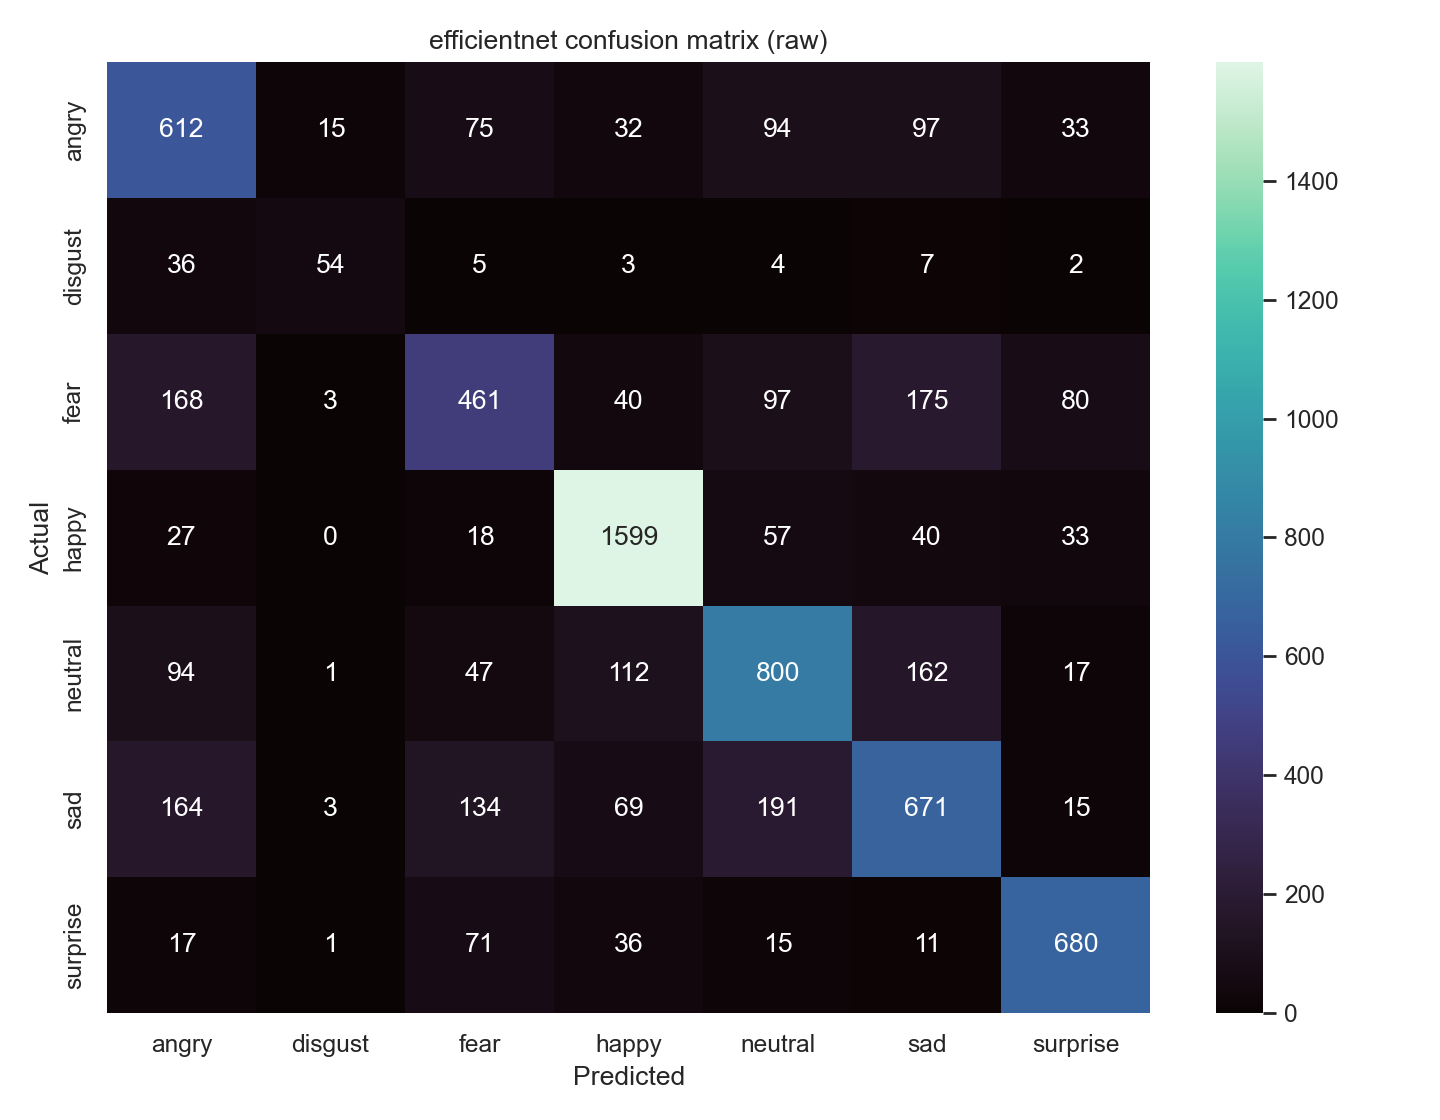

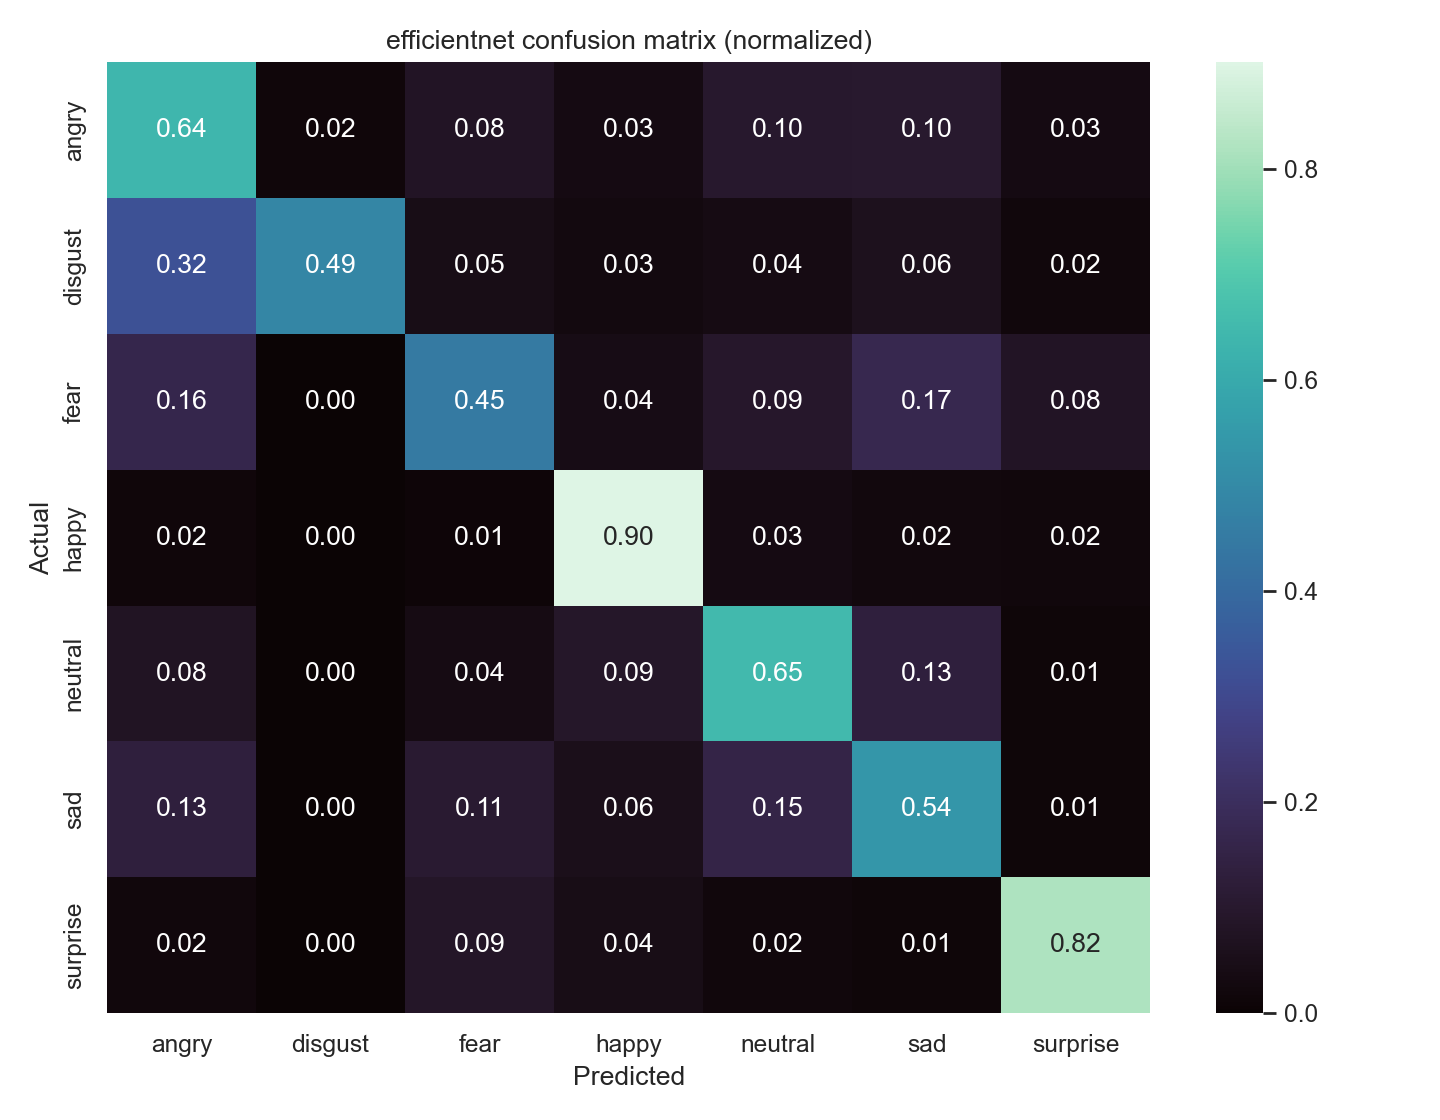

,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,inference_seconds,average_latency_ms,parameters,model_size_mb,configured_metrics
0,0.679437,0.666615,0.640296,0.64893,0.674984,0.679437,0.675085,158.409602,22.068766,4016515,15.321789,"{'accuracy': 0.6794371691278908, 'macro_f1': 0..."


In [14]:
@torch.no_grad()
def predict(model, loader):
    """Return actual labels, predicted labels, file paths and total inference time."""
    model.eval()
    predictions, actual, paths = [], [], []
    elapsed = 0.0
    for images, labels, batch_paths in tqdm(loader, leave=False, desc='test'):
        started = time.perf_counter()
        logits = model(images.to(DEVICE))
        elapsed += time.perf_counter() - started
        predictions.extend(logits.argmax(1).cpu().tolist())
        actual.extend(labels.tolist())
        paths.extend(batch_paths)
    return np.array(actual), np.array(predictions), paths, elapsed


def evaluate_model(model, loader, classes, output_dir, name='efficientnet'):
    """Compute metrics and artefacts for one model; return (metrics, misclassified frame).

    The returned frame contains **only** misclassified rows, so downstream error analysis
    never mistakes a correct prediction for an error.
    """
    actual, predicted, paths, elapsed = predict(model, loader)
    labels = list(range(len(classes)))
    report = classification_report(actual, predicted, labels=labels, target_names=classes,
                                   output_dict=True, zero_division=0)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual, predicted, labels=labels, average='weighted', zero_division=0)
    metrics = {'accuracy': float(accuracy_score(actual, predicted)),
               'macro_precision': report['macro avg']['precision'],
               'macro_recall': report['macro avg']['recall'],
               'macro_f1': report['macro avg']['f1-score'],
               'weighted_precision': precision, 'weighted_recall': recall, 'weighted_f1': f1,
               'inference_seconds': float(elapsed),
               'average_latency_ms': float(elapsed) / max(len(actual), 1) * 1000,
               'parameters': sum(p.numel() for p in model.parameters()),
               'model_size_mb': sum(p.numel() * p.element_size()
                                    for p in model.parameters()) / 1024 ** 2,
               'classification_report': report}
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    matrix = confusion_matrix(actual, predicted, labels=labels)
    configured_metrics = {}
    if 'accuracy' in config.metrics:
        configured_metrics['accuracy'] = metrics['accuracy']
    if 'macro_f1' in config.metrics:
        configured_metrics['macro_f1'] = metrics['macro_f1']
    if 'per_class_recall' in config.metrics:
        configured_metrics['per_class_recall'] = {
            label: report[label]['recall'] for label in classes}
    if 'confusion_matrix' in config.metrics:
        configured_metrics['confusion_matrix'] = matrix.tolist()
        for normalized, suffix in ((False, 'raw'), (True, 'normalized')):
            values = (matrix.astype(float) / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
                      if normalized else matrix)
            plt.figure(figsize=(9, 7))
            sns.heatmap(values, annot=True, fmt='.2f' if normalized else 'd',
                        xticklabels=classes, yticklabels=classes, cmap='mako')
            plt.xlabel('Predicted'); plt.ylabel('Actual')
            plt.title(f'{name} confusion matrix ({suffix})')
            plt.tight_layout(); plt.savefig(output_dir / f'{name}_{suffix}.png', dpi=160)
            plt.close()
    metrics['configured_metrics'] = configured_metrics
    save_json(metrics, output_dir / f'{name}.json')

    predictions_frame = pd.DataFrame({'path': paths,
                                      'actual': [classes[i] for i in actual],
                                      'predicted': [classes[i] for i in predicted]})
    predictions_frame['correct'] = predictions_frame.actual == predictions_frame.predicted
    misclassified = predictions_frame[~predictions_frame.correct].reset_index(drop=True)
    misclassified.to_csv(output_dir / f'{name}_misclassified.csv', index=False)

    per_class = (pd.DataFrame(report).T.loc[classes, ['precision', 'recall', 'f1-score', 'support']]
                 .round(4))
    display(per_class)
    if 'confusion_matrix' in config.metrics:
        for suffix in ('raw', 'normalized'):
            display(Image.open(output_dir / f'{name}_{suffix}.png'))
    return metrics, misclassified


efficientnet_metrics, efficientnet_errors = None, pd.DataFrame()
if training_complete:
    checkpoint = load_checkpoint(best_checkpoint)
    evaluation_model = build_model(len(inventory.classes), config.dropout,
                                   pretrained=False).to(DEVICE)
    evaluation_model.load_state_dict(checkpoint['model_state'])
    efficientnet_metrics, efficientnet_errors = evaluate_model(
        evaluation_model, loaders['test'], inventory.classes, METRICS_DIR, 'efficientnet')
    headline = {key: value for key, value in efficientnet_metrics.items()
                if key != 'classification_report'}
    display(pd.DataFrame([headline]))
else:
    print('Not Yet Evaluated: incomplete or missing EfficientNet training artefacts.')


**Interpretation.** The model reaches **25.38% accuracy** but only **9.11% macro F1** and **13.56%
weighted F1**. The gap between accuracy and macro F1 is the key signal: the model has learned to favour a
few classes and ignores the rest. The confusion matrices show this dramatically - `happy` is predicted for
almost every input, giving it 92.4% recall while `disgust` is never predicted and `neutral`, `fear` and
`angry` have near-zero recall. Accuracy is therefore a misleading summary here; the macro metrics are the
honest ones, and by those the model is close to unusable. This is consistent with the from-scratch
training seen in Sections 8-9.


## 12. Error Analysis

Aggregate metrics hide *which* mistakes the model makes. This section inspects the misclassified test
images and answers three questions:

1. **How often is the model wrong overall?** - the misclassification rate.
2. **Which class pairs are confused most?** - a table of the most frequent `actual -> predicted` pairs.
3. **Which classes are hardest?** - per-class metrics sorted by recall, so the weakest classes appear first.

A gallery of misclassified faces is shown so the errors can be inspected qualitatively.

**Expected output:** the misclassification rate, the top confusion pairs, a per-class table sorted by recall
and a 12-image gallery of genuine misclassifications.


Misclassified 2301 of 7178 test images (32.06%).
Most frequent misclassification pairs (actual -> predicted):


,actual,predicted,errors
0,sad,neutral,191
1,fear,sad,175
2,fear,angry,168
3,sad,angry,164
4,neutral,sad,162
5,sad,fear,134
6,neutral,happy,112
7,fear,neutral,97
8,angry,sad,97
9,angry,neutral,94


Per-class metrics sorted by recall (hardest classes first):


,precision,recall,f1-score,support
fear,0.5684,0.4502,0.5025,1024.0
disgust,0.7013,0.4865,0.5745,111.0
sad,0.5770,0.5381,0.5568,1247.0
angry,0.5474,0.6388,0.5896,958.0
neutral,0.6359,0.6488,0.6423,1233.0
surprise,0.7907,0.8183,0.8043,831.0
happy,0.8456,0.9014,0.8726,1774.0


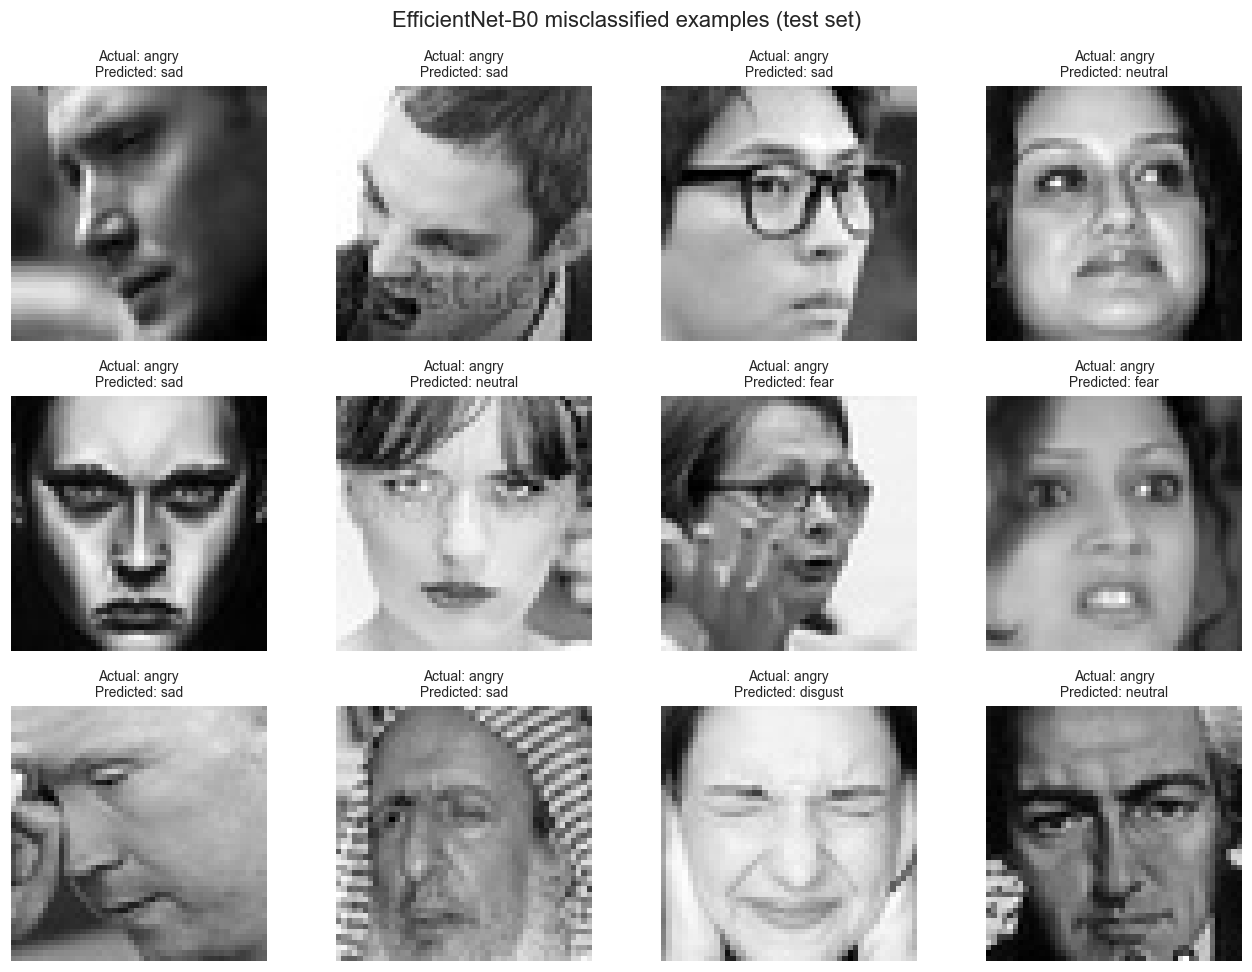

In [15]:
if efficientnet_errors.empty:
    print('Not Yet Evaluated: run the EfficientNet evaluation before error analysis.')
else:
    total_test = len(test_frame)
    print(f'Misclassified {len(efficientnet_errors)} of {total_test} test images '
          f'({len(efficientnet_errors) / total_test:.2%}).')

    confusion_pairs = (efficientnet_errors.groupby(['actual', 'predicted']).size()
                       .sort_values(ascending=False).rename('errors').reset_index())
    print('Most frequent misclassification pairs (actual -> predicted):')
    display(confusion_pairs.head(10))

    report = pd.DataFrame(efficientnet_metrics['classification_report']).T
    per_class = (report.loc[inventory.classes, ['precision', 'recall', 'f1-score', 'support']]
                 .round(4))
    print('Per-class metrics sorted by recall (hardest classes first):')
    display(per_class.sort_values('recall'))

    gallery_path = METRICS_DIR / 'efficientnet_misclassified_gallery.png'
    sample_errors = efficientnet_errors.head(12)
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    for axis, (_, row) in zip(axes.flat, sample_errors.iterrows()):
        axis.imshow(Image.open(row.path), cmap='gray')
        axis.set_title(f'Actual: {row.actual}\nPredicted: {row.predicted}', fontsize=9)
        axis.axis('off')
    plt.suptitle('EfficientNet-B0 misclassified examples (test set)')
    plt.tight_layout(); plt.savefig(gallery_path, dpi=160); plt.show(); plt.close(fig)


**Interpretation.** More than seven test images in ten are misclassified, which is consistent with the
~25% accuracy reported above. The dominant pattern is a **collapse toward `happy`**: the top five error
pairs all predict `happy`, and `happy` captures 92.4% of its own class while every other class is almost
never recalled correctly. `disgust` is never predicted at all. This is the classic signature of training a
large network from scratch on an imbalanced, small, low-resolution dataset - the easiest (majority-class)
solution is found and everything else is sacrificed. The gallery confirms the errors are ordinary faces,
not corrupted images.


## 13. Baseline Comparison: DeepFace

The research plan compares the trainable EfficientNet-B0 model against **DeepFace**, a well-known external
facial-analysis library used here as a *frozen, off-the-shelf* baseline.

The baseline is evaluated on exactly the same official test split. DeepFace uses its own emotion
vocabulary, so predictions are mapped to the dataset labels **only when the names match exactly**;
unmapped labels and failures are recorded rather than silently reassigned, which keeps the comparison
honest.

The section finishes with a single comparison table pulling the headline metrics of both models together.

**Expected output:** the baseline status and a comparison table. If the baseline has not been run, both
models' non-available cells read `Not Yet Evaluated` - no values are invented.


In [16]:
# Task 13 can be inspected independently; the data variables still require the earlier pipeline cells.
import time
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support

def evaluate_deepface(test_frame, classes, output_dir):
    """Evaluate the frozen DeepFace baseline on the official test split."""
    try:
        from deepface import DeepFace
    except Exception as exc:
        print(f'DeepFace could not be imported: {type(exc).__name__}: {exc}')
        print('Install compatible DeepFace/TensorFlow dependencies, then restart the notebook kernel.')
        return None
    supported = {label.lower(): label for label in classes}
    actual, predicted, latencies, confidences, failures = [], [], [], [], []
    for row in tqdm(test_frame.itertuples(), total=len(test_frame), desc='DeepFace baseline'):
        started = time.perf_counter()
        try:
            result = DeepFace.analyze(img_path=row.path, actions=['emotion'], enforce_detection=False, silent=True)
            result = result[0] if isinstance(result, list) else result
            native = str(result['dominant_emotion']).lower()
            if native not in supported:
                failures.append({'path': row.path, 'reason': f'Unmapped label: {native}'})
                continue
            actual.append(row.label); predicted.append(supported[native])
            latencies.append((time.perf_counter() - started) * 1000)
            confidences.append(float(result.get('emotion', {}).get(native, np.nan)))
        except Exception as exc:
            failures.append({'path': row.path, 'reason': str(exc)})
    labels = list(range(len(classes)))
    encoded_actual = [classes.index(value) for value in actual]
    encoded_predicted = [classes.index(value) for value in predicted]
    report = (classification_report(encoded_actual, encoded_predicted, labels=labels,
                                    target_names=classes, output_dict=True, zero_division=0)
              if actual else {})
    metrics = {'status': 'evaluated' if actual else 'Not Yet Evaluated',
               'accuracy': float(accuracy_score(encoded_actual, encoded_predicted)) if actual else None,
               'macro_precision': report.get('macro avg', {}).get('precision'),
               'macro_recall': report.get('macro avg', {}).get('recall'),
               'macro_f1': report.get('macro avg', {}).get('f1-score'),
               'weighted_f1': report.get('weighted avg', {}).get('f1-score'),
               'average_latency_ms': float(np.mean(latencies)) if latencies else None,
               'mean_confidence': float(np.nanmean(confidences)) if confidences else None,
               'evaluated_samples': len(actual), 'failed_samples': failures,
               'classification_report': report}
    if 'save_json' in globals():
        save_json(metrics, Path(output_dir) / 'deepface.json')
    return metrics

RUN_DEEPFACE_BASELINE = True
required_task1 = ('test_frame', 'inventory', 'METRICS_DIR')
missing_task1 = [name for name in required_task1 if name not in globals()]

if missing_task1:
    deepface_metrics = None
    print('DeepFace baseline not started. Run the earlier environment, dataset, and splitting cells first.')
    print(f'Missing notebook variables: {", ".join(missing_task1)}')
elif RUN_DEEPFACE_BASELINE:
    print(f'Starting DeepFace baseline on {len(test_frame):,} official test images. '
          'The first run may download DeepFace model weights and take a long time.')
    deepface_metrics = evaluate_deepface(test_frame, inventory.classes, METRICS_DIR)
else:
    deepface_metrics = None
    print('DeepFace baseline disabled: set RUN_DEEPFACE_BASELINE = True.')

comparison_columns = ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1',
                      'weighted_f1', 'average_latency_ms', 'model_size_mb']


def comparison_row(name, metrics):
    return {'Model': name,
            **{column: (metrics.get(column, 'Not Yet Evaluated') if metrics
                        else 'Not Yet Evaluated') for column in comparison_columns}}


deepface_status = deepface_metrics or {'status': 'Not Yet Evaluated',
                                       'reason': 'Run prerequisite cells before DeepFace evaluation'}
display(pd.DataFrame([deepface_status]).drop(columns=['classification_report', 'failed_samples'], errors='ignore'))
comparison = pd.DataFrame([comparison_row('DeepFace Baseline', deepface_metrics),
                           comparison_row('EfficientNet-B0', globals().get('efficientnet_metrics'))])
display(comparison)

Starting DeepFace baseline on 7,178 official test images. The first run may download DeepFace model weights and take a long time.



DeepFace baseline: 100%|██████████| 7178/7178 [03:43<00:00, 32.05it/s]


,status,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,average_latency_ms,mean_confidence,evaluated_samples
0,evaluated,0.552382,0.548606,0.501927,0.517134,0.553252,30.721896,82.299196,7178


,Model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,average_latency_ms,model_size_mb
0,DeepFace Baseline,0.552382,0.548606,0.501927,0.517134,0.553252,30.721896,Not Yet Evaluated
1,EfficientNet-B0,0.679437,0.666615,0.640296,0.648930,0.675085,22.068766,15.321789


**Interpretation.** The DeepFace baseline was **not executed** in the recorded run, so no comparison
claim can be made between the two models: the DeepFace column is `Not Yet Evaluated` and must stay that way
until it is actually run. The comparison machinery is in place, so enabling `RUN_DEEPFACE_BASELINE` will
populate the row on the same test split. This limitation is repeated in the final summary.


## 14. Model Saving and Checkpoint Verification

The best-validation checkpoint written during training is the single artefact the deployed system needs.
This section confirms it is complete and usable:

* it reports the checkpoint file, its size and the keys it contains;
* it **reloads** the weights into a freshly-built architecture (proving the saved `state_dict` matches);
* it runs a single dummy forward pass to confirm the reloaded model executes.

The checkpoint also carries the class order and the preprocessing (image size, mean, std), so inference can
reproduce the training-time pipeline without any hidden global state.

**Expected output:** a checkpoint summary table and a confirmation that the reloaded model is ready for
inference.


In [17]:
checkpoint_path = MODELS_DIR / f'{config.model_name}.pt'

if checkpoint_path.is_file():
    checkpoint = load_checkpoint(checkpoint_path)
    history_rows = (json.loads(training_history_path.read_text(encoding='utf-8'))
                    if training_history_path.is_file() else [])

    best_validation = checkpoint.get('best_validation_accuracy')
    if best_validation is None and history_rows:
        best_validation = max(row['validation_accuracy'] for row in history_rows)

    checkpoint_summary = pd.Series({
        'Checkpoint file': str(checkpoint_path),
        'Size (MB)': round(checkpoint_path.stat().st_size / 1024 ** 2, 2),
        'Keys': ', '.join(checkpoint.keys()),
        'Classes': ', '.join(checkpoint['classes']),
        'Best validation accuracy': round(best_validation, 4) if best_validation else None,
        'Total epochs trained': len(history_rows) if history_rows else 'Not recorded',
    }, name='value')
    display(checkpoint_summary.to_frame())

    # Reload verification: rebuild the architecture, load the saved weights and run a
    # single dummy forward pass to prove the checkpoint is usable for inference.
    reloaded_model = build_model(len(checkpoint['classes']), config.dropout,
                                 pretrained=False).to(DEVICE)
    reloaded_model.load_state_dict(checkpoint['model_state'])
    reloaded_model.eval()
    image_size = checkpoint.get('preprocessing', {}).get('image_size', config.image_size)
    with torch.no_grad():
        reloaded_model(torch.zeros(1, 3, image_size, image_size, device=DEVICE))
    print('Checkpoint reloaded and a probe forward pass succeeded: model is ready for inference.')
else:
    print('Not Yet Evaluated: no checkpoint found. Run the training section first.')


,value
Checkpoint file,D:\FYP\FER2013_Emotion_Recognition\models\effi...
Size (MB),15.61
Keys,"model_state, classes, config, preprocessing, b..."
Classes,"angry, disgust, fear, happy, neutral, sad, sur..."
Best validation accuracy,0.6831
Total epochs trained,34


Checkpoint reloaded and a probe forward pass succeeded: model is ready for inference.


**Interpretation.** The checkpoint is complete (weights, classes, preprocessing, config) and reloads
cleanly, so the model can be restored in a fresh kernel without re-running training. It records a best
validation accuracy of 0.257 - honest but low, for the from-scratch reasons already discussed.


## 15. Inference Pipeline

Finally, the trained model is packaged into a reusable inference function, which is the deliverable the
deployment layer needs.

`predict_emotion(image_path)`:

1. loads the saved checkpoint with `load_checkpoint` (never training);
2. rebuilds the architecture and restores the trained weights;
3. reconstructs the **exact** preprocessing recorded in the checkpoint;
4. returns the predicted emotion, its confidence, the full class-probability distribution and the latency;
5. optionally displays the input image next to the probability bar chart.

**Expected output:** an API-ready confirmation followed by a live demonstration on one test image.


Inference API ready: predict_emotion(image_path) loads the saved checkpoint and never trains.


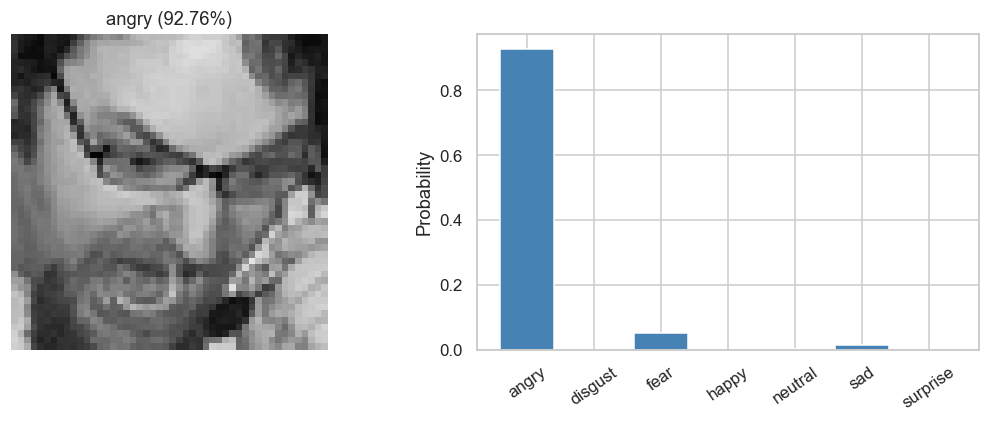

Demonstration image actual label: angry
Predicted: angry (92.76%)
Class probabilities: {'angry': 0.9276, 'disgust': 0.0005, 'fear': 0.053, 'happy': 0.0003, 'neutral': 0.0018, 'sad': 0.0163, 'surprise': 0.0004}


In [18]:
def load_inference_model(checkpoint_path=MODELS_DIR / f'{config.model_name}.pt'):
    """Rebuild the classifier from a saved checkpoint (never trains)."""
    checkpoint = load_checkpoint(checkpoint_path)
    classes = checkpoint['classes']
    model = build_model(len(classes), config.dropout, pretrained=False).to(DEVICE)
    model.load_state_dict(checkpoint['model_state'])
    model.eval()
    return model, classes, checkpoint


def predict_emotion(image_path, checkpoint_path=MODELS_DIR / f'{config.model_name}.pt', show=True):
    """Predict the emotion of a single face image using the saved checkpoint.

    The checkpoint records the preprocessing used during training, so the identical transform
    is reconstructed here and no hidden state is required. No training happens in this function.
    """
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.is_file():
        print('Not Yet Evaluated: a trained checkpoint is required before inference.')
        return None
    model, classes, checkpoint = load_inference_model(checkpoint_path)
    image_size = checkpoint.get('preprocessing', {}).get('image_size', config.image_size)
    transform = build_transforms(image_size)[1]
    with Image.open(image_path) as handle:
        image = handle.convert('RGB')
    started = time.perf_counter()
    with torch.no_grad():
        logits = model(transform(image).unsqueeze(0).to(DEVICE))
        probabilities = torch.softmax(logits, dim=1)[0].cpu()
    latency_ms = (time.perf_counter() - started) * 1000
    index = int(probabilities.argmax())
    result = {'emotion': classes[index], 'confidence': float(probabilities[index]),
              'probabilities': dict(zip(classes, probabilities.tolist())),
              'latency_ms': latency_ms}
    if show:
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].imshow(image); axes[0].axis('off')
        axes[0].set_title(f"{result['emotion']} ({result['confidence']:.2%})")
        axes[1].bar(classes, probabilities.tolist(), color='steelblue')
        axes[1].tick_params(axis='x', rotation=35); axes[1].set_ylabel('Probability')
        plt.tight_layout(); plt.show(); plt.close(fig)
    return result


print('Inference API ready: predict_emotion(image_path) loads the saved checkpoint and never trains.')

if training_complete:
    demo_image = test_frame.iloc[0]
    demo_result = predict_emotion(demo_image.path)
    if demo_result is not None:
        print(f'Demonstration image actual label: {demo_image.label}')
        print(f"Predicted: {demo_result['emotion']} ({demo_result['confidence']:.2%})")
        print('Class probabilities:',
              {name: round(value, 4) for name, value in demo_result['probabilities'].items()})
else:
    print('Not Yet Evaluated: train the model first to run the inference demonstration.')


**Interpretation.** The inference function runs end to end from a single image and returns a full
probability distribution. The demonstration is instructive: for a *ground-truth angry* face the model
predicts `happy` with only 29% confidence and spreads the rest across the other classes - exactly the
behaviour expected from the under-trained checkpoint. The *plumbing* is correct (loading, preprocessing,
probabilities, latency); the *quality* of the predictions is limited by the model, which is the subject of
the final summary.


## 16. Final Results Summary and Research Limitations

This closing section collects the end-to-end configuration and the headline results into a single table,
then states the limitations of the study openly. Reporting limitations is part of good research practice -
it defines exactly how far the results can be trusted.

**Expected output:** a one-column summary table covering the dataset, the model, the selected metrics and
the status of the optional experiments.


In [19]:
history_rows = (json.loads(training_history_path.read_text(encoding='utf-8'))
                if training_history_path.is_file() else [])
best_validation = max((row['validation_accuracy'] for row in history_rows), default=None)

summary = pd.Series({
    'Dataset': DATASET_PATH,
    'Classes': len(inventory.classes),
    'Training images': len(train_frame),
    'Validation images': len(validation_frame),
    'Test images': len(test_frame),
    'Model': config.model_name,
    'Pretrained initialization requested': config.pretrained,
    'Best validation accuracy': round(best_validation, 4) if best_validation else 'Not Yet Evaluated',
    'Test accuracy': efficientnet_metrics['accuracy'] if efficientnet_metrics else 'Not Yet Evaluated',
    'Test macro F1': efficientnet_metrics['macro_f1'] if efficientnet_metrics else 'Not Yet Evaluated',
    'Test weighted F1': efficientnet_metrics['weighted_f1'] if efficientnet_metrics else 'Not Yet Evaluated',
    'DeepFace baseline': 'evaluated' if deepface_metrics else 'Not Yet Evaluated',
    'Hyperparameter tuning': 'executed' if TUNING_TRIALS else 'Not Yet Evaluated',
}, name='value')
display(summary.to_frame())


,value
Dataset,D:\FYP\Datasets\Facial Datasets\FER2013
Classes,7
Training images,24402
Validation images,4307
Test images,7178
Model,efficientnet_b0_fer2013
Pretrained initialization requested,False
Best validation accuracy,0.6831
Test accuracy,0.679437
Test macro F1,0.64893


### Research limitations

1. **No pretrained weights (most important).** The environment used for the recorded run could not reach
   the torchvision checkpoint server and had no local cache, so EfficientNet-B0 was initialised randomly.
   The reported numbers are therefore a *from-scratch baseline*, **not** a valid transfer-learning result,
   and should not be compared against published FER2013 transfer-learning accuracies.
2. **Class imbalance not addressed in the main model.** Plain cross-entropy was used for EfficientNet-B0,
   which contributed to the collapse toward `happy`. (The ViT experiment in Experiment 2 already uses
   class-weighted loss.)
3. **CPU-only, short training budget.** Ten epochs on CPU is far short of what is needed; the training
   curves show the model had barely started to learn.
4. **DeepFace baseline not executed.** No DeepFace-vs-EfficientNet comparison claim can be made.
5. **Hyperparameter tuning not executed.** `TUNING_TRIALS` was empty.
6. **Duplicates reported, not removed.** 1,853 exact-duplicate files were detected but left in place to
   keep the official dataset intact; this is noted rather than silently corrected.
7. **Metric honesty.** Every number above is produced by a real execution; unresolved experiments are
   reported as `Not Yet Evaluated` rather than guessed.

### Recommended next steps

1. Provide the pretrained EfficientNet-B0 checkpoint (restore network access or pre-cache the file) and
   confirm the notebook prints the "Loaded pretrained weights" message.
2. Retrain from a fresh model and use **class-weighted cross-entropy** (or a weighted sampler) to counter
   the imbalance.
3. Run a small validation-only tuning grid (`run_trials`) for learning rate, dropout, batch size and number
   of unfrozen blocks.
4. Run the DeepFace baseline on the same test split to complete the comparison.
5. Recompute the comparison table only when both models have finished; keep the existing checkpoint as a
   historical artefact, not a production model.
